In [16]:
import tensorflow as tf 
import keras as ks
import numpy as np 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import (
Input,
Conv2D,
MaxPooling2D,
Flatten,
Dense)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import image_dataset_from_directory,img_to_array
import matplotlib.pyplot as plt

In [2]:
IMG_SIZE=128
BATCH_SIZE=32
train_path = "Datasets/xray_dataset_covid19/train"
test_path="Datasets/xray_dataset_covid19/test"

In [3]:
train_data=image_dataset_from_directory(
    train_path,
    image_size=(IMG_SIZE,IMG_SIZE),
    label_mode="binary",
    shuffle=True,
    batch_size=BATCH_SIZE
)

Found 148 files belonging to 2 classes.


In [4]:
test_data=image_dataset_from_directory(
    test_path,
    image_size=(IMG_SIZE,IMG_SIZE),
    label_mode="binary",
    shuffle=False,
    batch_size=BATCH_SIZE
)

Found 40 files belonging to 2 classes.


In [5]:
normalization = tf.keras.layers.Rescaling(
    1.0/255.0
)

In [6]:
train_data = train_data.map(lambda x , y : (normalization(x),y))
test_data = test_data.map( lambda x , y : (normalization(x),y))

In [7]:
model=Sequential()
model.add(Input(shape=(IMG_SIZE,IMG_SIZE,3)))
model.add(Conv2D(32,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Conv2D(128,(3,3),activation='relu'))
model.add(MaxPooling2D(2,2))
model.add(Flatten())
model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(32,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [8]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [9]:
history = model.fit(train_data,epochs=10,validation_data=test_data,verbose=1)

C:\Users\Nishi.M. Waghwani\Nishi -Ty\mlenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - accuracy: 0.5541 - loss: 0.8166 - val_accuracy: 0.6000 - val_loss: 0.6502
Epoch 2/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 990ms/step - accuracy: 0.5743 - loss: 0.6779 - val_accuracy: 1.0000 - val_loss: 0.6365
Epoch 3/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 967ms/step - accuracy: 0.8041 - loss: 0.6355 - val_accuracy: 1.0000 - val_loss: 0.5302
Epoch 4/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 829ms/step - accuracy: 0.9054 - loss: 0.5043 - val_accuracy: 0.9500 - val_loss: 0.3160
Epoch 5/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 941ms/step - accuracy: 0.7635 - loss: 0.4813 - val_accuracy: 1.0000 - val_loss: 0.1448
Epoch 6/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.8446 - loss: 0.3346 - val_accuracy: 1.0000 - val_loss: 0.1342
Epoch 7/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 10s 810ms/step - accuracy: 0.9054 - loss: 0.2220 - val_accuracy: 0.9750 - val_loss: 0.1039
Epoch 8/10
5/5 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.9459 - loss: 0.1333 - val_accuracy: 1.0000 - val_loss: 

In [10]:
loss,accuracy=model.evaluate(test_data)
print(loss)
print(accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 1.0000 - loss: 0.0296
0.029632389545440674
1.0


Pnemounia
Normal 0.86864424
pnemounia 0.13135576


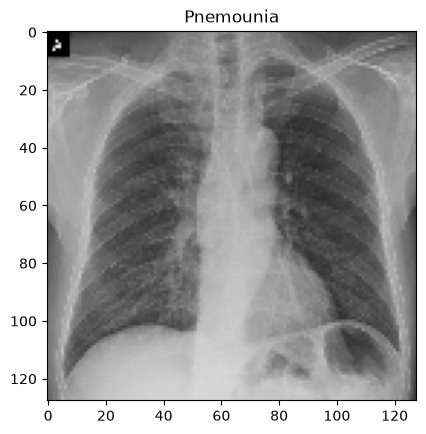

In [22]:
img_path = r"C:\Users\Nishi.M. Waghwani\Nishi -Ty\ANNDL\Datasets\xray_dataset_covid19\test\PNEUMONIA\ryct.2020200034.fig2.jpeg"
img=tf.keras.utils.load_img(
    img_path,
    target_size=(IMG_SIZE,IMG_SIZE)
)
img_array=tf.keras.utils.img_to_array(img)
img_array=img_array/255.0
img_array=np.expand_dims(img_array,axis=0)
op=model.predict(img_array,verbose=0)
prob=op[0][0]
if prob >0.5:
    print("Pnemounia")
    print("Normal",prob)
    print("pnemounia",1-prob)
else:
    print("Normal")
    print("Normal",prob)
    print("pnemounia",1-prob)
plt.imshow(img)
plt.title("Pnemounia" if prob>0.5 else "Normal")
plt.axis=("off")
plt.show()


In [23]:
model.save("xray.keras")